# 은행 고객 이탈 예측

## 데이터 불러오기

In [1]:
# 파이썬 경고 무시 설정
import warnings
warnings.filterwarnings('ignore')

In [2]:
# 필요한 라이브러리 임포트
import pandas as pd

# 파일 경로 설정
file_path=r'C:\python\work\bank2\10\Churn_Modelling.csv'

# DataFrame 생성
df = pd.read_csv(file_path)

# 결과 확인
display(df)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


## 데이터 전처리

In [3]:
# DataFrame -> 전용 함수 -> 기본 정보(행과 열) 제공(print 내장) -> info() 함수
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
# 각 컬럼별 누락 데이터 확인

## df.isnull()sum()
num_nulls = df.isnull().sum()
print(f'각 컬럼별 누락 데이터의 수: \n{num_nulls}')


각 컬럼별 누락 데이터의 수: 
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [5]:
# Age 컬럼의 연령별 분포 -> value_counts()
age_counts = df['Age'].value_counts().head(n=10)
print(f'Age 컬럼의 연령별 분포 Top 10: \n{age_counts}')

# df.head(n=10) -> 위에서 부터 n개 출력 -> Top n 출력

Age 컬럼의 연령별 분포 Top 10: 
Age
37    478
38    477
35    474
36    456
34    447
33    442
40    432
39    423
32    418
31    404
Name: count, dtype: int64


In [6]:
# 숫자값으로 된 컬럼 -> 누락 데이터 없음 -> 중간값 또는 최빈수(가장 빈도가 높음) 확인
# Age컬럼 -> 요약 통계량 추출
age_stats = df['Age'].describe()
print(f'Age 컬럼의 요약 통계량: \n{age_stats}')


Age 컬럼의 요약 통계량: 
count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: Age, dtype: float64


Age_step
0       0
1      89
2    1879
3    4451
4    2320
5     797
6     331
7     133
Name: count, dtype: int64

,수량,비율(%)
Age_step,,
0,0,0.00
1,89,0.89
2,1879,18.79
3,4451,44.51
4,2320,23.20
5,797,7.97
6,331,3.31
7,133,1.33


<Axes: title={'center': 'Age Group Distribution'}, xlabel='Age Step', ylabel='Count'>

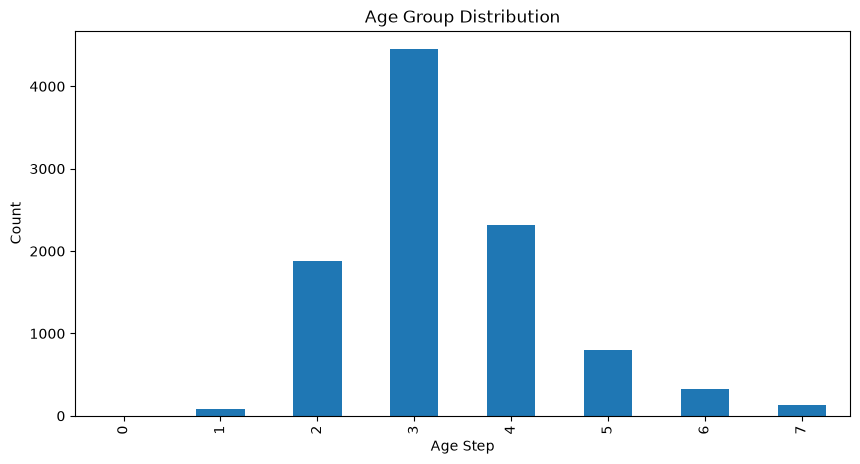

In [7]:
# Age컬럼 -> 구간화 -> 8단계
# 데이터프레임 복사
df1 = df.copy()

# 구간화
df1['Age_step'] = pd.cut(
    x=df1['Age'],
    bins=[0, 10, 20, 30, 40, 50, 60, 70, 100],
    labels=[0, 1, 2, 3, 4, 5, 6, 7],
    include_lowest=True
)

# 구간별 수량 확인
display(df1['Age_step'].value_counts().sort_index())

# 구간별 수량
age_count = df1['Age_step'].value_counts().sort_index()

# 구간별 비율(%)
age_ratio = df1['Age_step'].value_counts(normalize=True).sort_index() * 100

# 결과 DataFrame 생성
age_result = pd.DataFrame({
    '수량': age_count,
    '비율(%)': age_ratio
})

display(age_result)

age_count.plot(
    kind='bar',
    figsize=(10, 5),
    title='Age Group Distribution',
    xlabel='Age Step',
    ylabel='Count'
)

In [8]:
# Age_step 기준으로 1, 6, 7 구간 데이터 삭제

## 삭제 대상 구간 설정
remove_steps = [1, 6, 7]

## 삭제 전 데이터 수량 확인
print(f'삭제 전 데이터 수량: {len(df1)}')

## 삭제 대상 구간의 데이터 수량 확인
print(df1[df1['Age_step'].isin(remove_steps)].shape[0])

## 삭제 대상 구간을 제외한 데이터 생성
df2 = df1[~df1['Age_step'].isin(remove_steps)].copy()

## 인덱스 초기화
df2.reset_index(drop=True, inplace=True)

## 전처리 결과 확인
print(f'삭제 후 데이터 수량: {len(df2)}')
print(f'삭제된 데이터 수량: {len(df1) - len(df2)}')

## 구간별 잔여 데이터 수량 확인
display(df2['Age_step'].value_counts().sort_index())

## 최종 데이터 확인
display(df2)

삭제 전 데이터 수량: 10000
553
삭제 후 데이터 수량: 9447
삭제된 데이터 수량: 553


Age_step
0       0
1       0
2    1879
3    4451
4    2320
5     797
6       0
7       0
Name: count, dtype: int64

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_step
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,4
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,4
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,4
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,3
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9442,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,3
9443,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,3
9444,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,3
9445,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,4


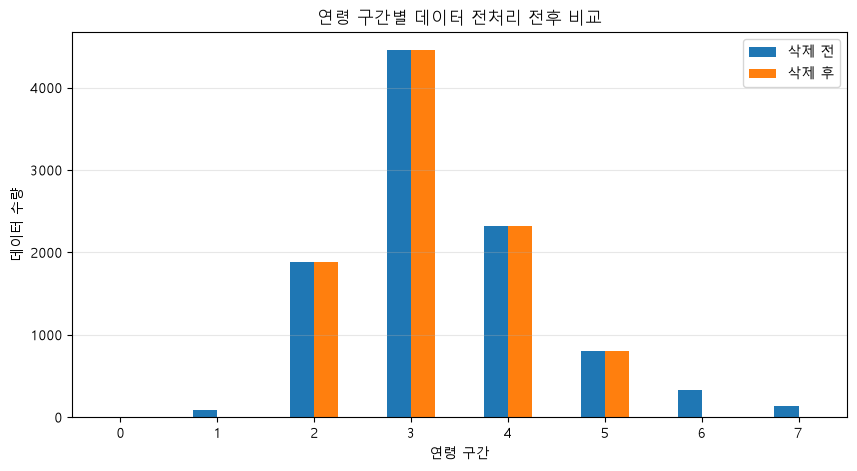

In [9]:
# 한글 폰트 설정
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 삭제 전 구간별 수량
before_count = df1['Age_step'].value_counts().sort_index()

# 삭제 후 구간별 수량
after_count = df2['Age_step'].value_counts().sort_index()

# 비교용 데이터프레임 생성
age_compare = pd.DataFrame({
    '삭제 전': before_count,
    '삭제 후': after_count
}).fillna(0)

# 막대그래프 시각화
age_compare.plot(
    kind='bar',
    figsize=(10, 5),
    title='연령 구간별 데이터 전처리 전후 비교',
    xlabel='연령 구간',
    ylabel='데이터 수량',
    rot=0
)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

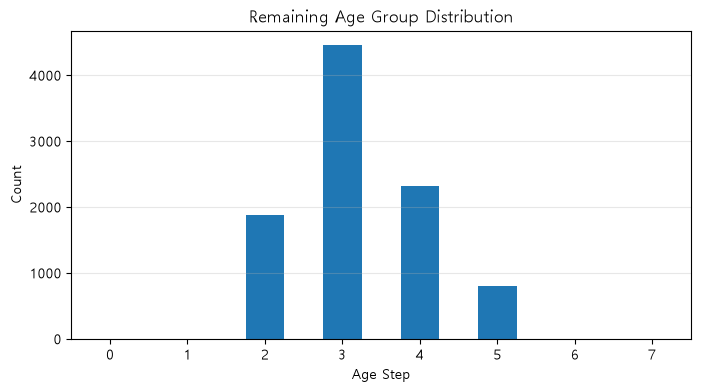

In [10]:
# 삭제 후 구간별 수량 확인
after_count = df2['Age_step'].value_counts().sort_index()

# 막대그래프
after_count.plot(
    kind='bar',
    figsize=(8, 4),
    title='Remaining Age Group Distribution',
    xlabel='Age Step',
    ylabel='Count',
    rot=0
)

plt.grid(axis='y', alpha=0.3)
plt.show()

In [11]:
# 불필요한 컬럼 삭제
## RowNumber : 데이터의 행 번호로 분석에 불필요
## CustomerId : 고객 고유 식별번호로 예측 변수로 사용하기 어려움
## Surname : 고객 성씨로 분석 목적과 직접적인 관련성이 낮음

df2.drop(
    columns=['RowNumber', 'CustomerId', 'Surname'],
    inplace=True
)

# 삭제 결과 확인
display(df2.head())

# 최종 컬럼 확인
print(df2.columns)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_step
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,4
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,4
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,4
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,3
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,4


Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited', 'Age_step'],
      dtype='object')


In [12]:
# 전체 컬럼의 데이터 타입 확인
print(df2.dtypes)

# 범주형 데이터 컬럼 확인
display(df2.select_dtypes(include=['object', 'category']).head())

# 범주형 컬럼별 고유값 개수 확인
for col in df2.select_dtypes(include=['object', 'category']).columns:
    print(f'{col}: {df2[col].nunique()}개')
    print(df2[col].unique())
    print('-' * 50)

display(df1)
display(df2)

CreditScore           int64
Geography            object
Gender               object
Age                   int64
Tenure                int64
Balance             float64
NumOfProducts         int64
HasCrCard             int64
IsActiveMember        int64
EstimatedSalary     float64
Exited                int64
Age_step           category
dtype: object


,Geography,Gender,Age_step
0,France,Female,4
1,Spain,Female,4
2,France,Female,4
3,France,Female,3
4,Spain,Female,4


Geography: 3개
['France' 'Spain' 'Germany']
--------------------------------------------------
Gender: 2개
['Female' 'Male']
--------------------------------------------------
Age_step: 4개
[4, 3, 2, 5]
Categories (8, int64): [0 < 1 < 2 < 3 < 4 < 5 < 6 < 7]
--------------------------------------------------


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_step
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,4
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,4
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,4
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,3
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,3
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,3
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,3
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,4


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_step
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,4
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,4
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,4
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,3
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...
9442,771,France,Male,39,5,0.00,2,1,0,96270.64,0,3
9443,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,3
9444,709,France,Female,36,7,0.00,1,0,1,42085.58,1,3
9445,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,4


## Encoding

In [13]:
# One-Hot Encoding
## Geography : 국가별 지역 정보 (France, Germany, Spain)
## Gender : 성별 정보 (Male, Female)
## 두 컬럼 모두 순서가 없는 범주형 데이터이므로 One-Hot Encoding 적용

df2 = pd.get_dummies(
    df2,
    columns=['Geography', 'Gender'],
    dtype=int
)

# 인코딩 결과 확인
display(df2.head())

# 변경된 컬럼 확인
print(df2.columns)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_step,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,4,1,0,0,1,0
1,608,41,1,83807.86,1,0,1,112542.58,0,4,0,0,1,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,4,1,0,0,1,0
3,699,39,1,0.00,2,0,0,93826.63,0,3,1,0,0,1,0
4,850,43,2,125510.82,1,1,1,79084.10,0,4,0,0,1,1,0


Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited', 'Age_step',
       'Geography_France', 'Geography_Germany', 'Geography_Spain',
       'Gender_Female', 'Gender_Male'],
      dtype='object')


## 데이터 탐색 및 EDA

In [15]:
# 그래프 작성에 필요한 라이브러리
import matplotlib.pyplot as plt
import pandas as pd

# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

#### 시각화용 데이터 생성

In [16]:
# 인코딩 전 데이터 복사
df_plot = df1.copy()

# Age_step에서 1, 6, 7 그룹 제거
remove_steps = [1, 6, 7]
df_plot = df_plot[~df_plot['Age_step'].isin(remove_steps)].copy()

# 인덱스 초기화
df_plot.reset_index(drop=True, inplace=True)

# 데이터 확인
display(df_plot.head())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_step
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,4
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,4
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,4
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,3
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,4


#### 연령 그룹별 이탈률 그래프

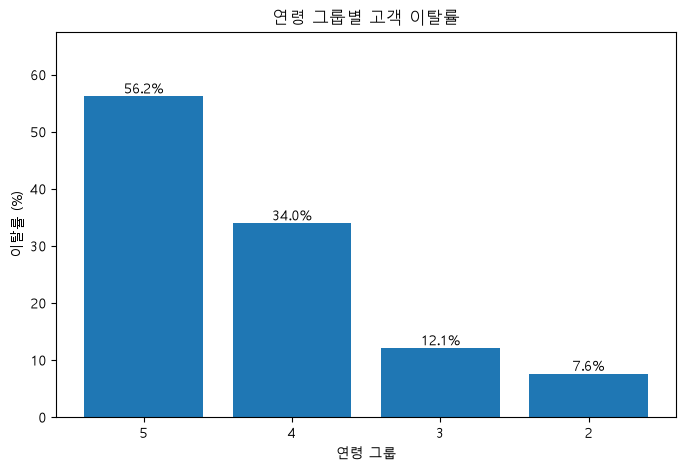

In [17]:
# 연령 그룹별 이탈률 계산
age_result = df_plot.groupby('Age_step', observed=True)['Exited'].mean() * 100

# 이탈률 내림차순 정렬
age_result = age_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(8, 5))
bars = plt.bar(age_result.index.astype(str), age_result.values)

# 막대 위에 이탈률 표시
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.title('연령 그룹별 고객 이탈률')
plt.xlabel('연령 그룹')
plt.ylabel('이탈률 (%)')
plt.ylim(0, age_result.max() * 1.2)
plt.show()

#### 성별 이탈률

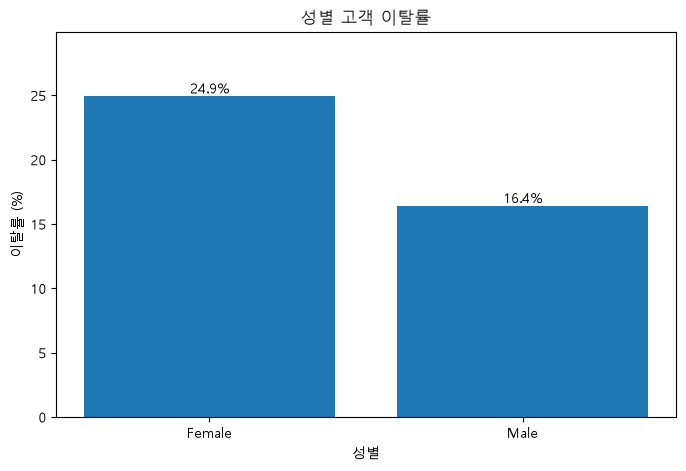

In [18]:
# 성별 이탈률 계산
gender_result = df_plot.groupby('Gender')['Exited'].mean() * 100

# 이탈률 내림차순 정렬
gender_result = gender_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(8, 5))
bars = plt.bar(gender_result.index, gender_result.values)

# 막대 위에 이탈률 표시
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{bar.get_height():.1f}%', ha='center', va='bottom')

plt.title('성별 고객 이탈률')
plt.xlabel('성별')
plt.ylabel('이탈률 (%)')
plt.ylim(0, gender_result.max() * 1.2)
plt.show()

#### 지역별 이탈률

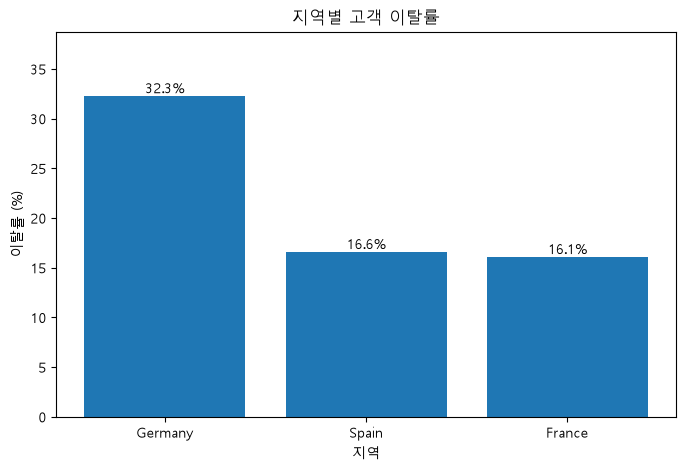

In [19]:
# 지역별 이탈률 계산
geo_result = df_plot.groupby('Geography')['Exited'].mean() * 100

# 이탈률 내림차순 정렬
geo_result = geo_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(8, 5))
bars = plt.bar(geo_result.index, geo_result.values)

# 막대 위에 이탈률 표시
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{bar.get_height():.1f}%', ha='center', va='bottom')

plt.title('지역별 고객 이탈률')
plt.xlabel('지역')
plt.ylabel('이탈률 (%)')
plt.ylim(0, geo_result.max() * 1.2)
plt.show()

#### 보유 상품 수별 이탈률

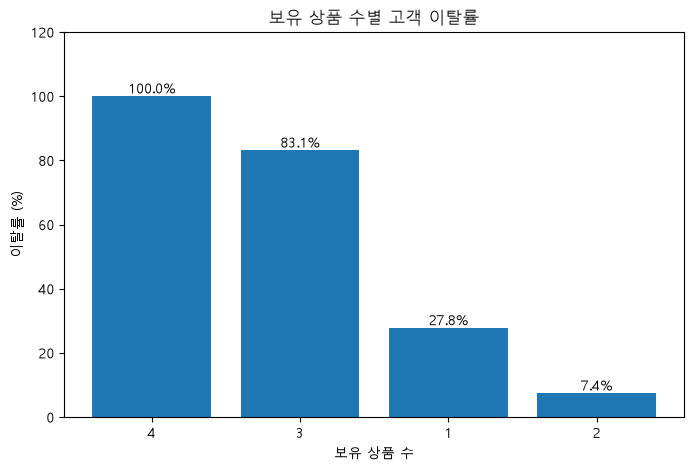

In [20]:
# 보유 상품 수별 이탈률 계산
product_result = df_plot.groupby('NumOfProducts')['Exited'].mean() * 100

# 이탈률 내림차순 정렬
product_result = product_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(8, 5))
bars = plt.bar(product_result.index.astype(str), product_result.values)

# 막대 위에 이탈률 표시
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{bar.get_height():.1f}%', ha='center', va='bottom')

plt.title('보유 상품 수별 고객 이탈률')
plt.xlabel('보유 상품 수')
plt.ylabel('이탈률 (%)')
plt.ylim(0, product_result.max() * 1.2)
plt.show()

#### 거래 기간별 이탈률

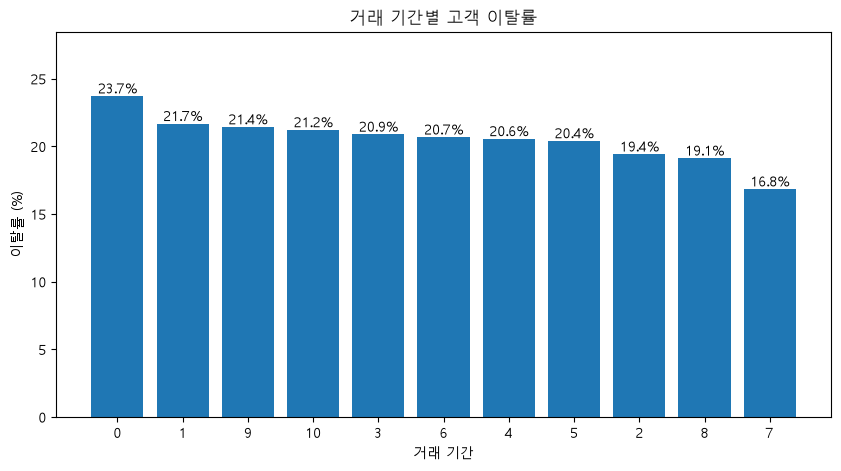

In [21]:
# 거래 기간별 이탈률 계산
tenure_result = df_plot.groupby('Tenure')['Exited'].mean() * 100

# 이탈률 내림차순 정렬
tenure_result = tenure_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(10, 5))
bars = plt.bar(tenure_result.index.astype(str), tenure_result.values)

# 막대 위에 이탈률 표시
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{bar.get_height():.1f}%', ha='center', va='bottom')

plt.title('거래 기간별 고객 이탈률')
plt.xlabel('거래 기간')
plt.ylabel('이탈률 (%)')
plt.ylim(0, tenure_result.max() * 1.2)
plt.show()

활성 회원 여부별 이탈률

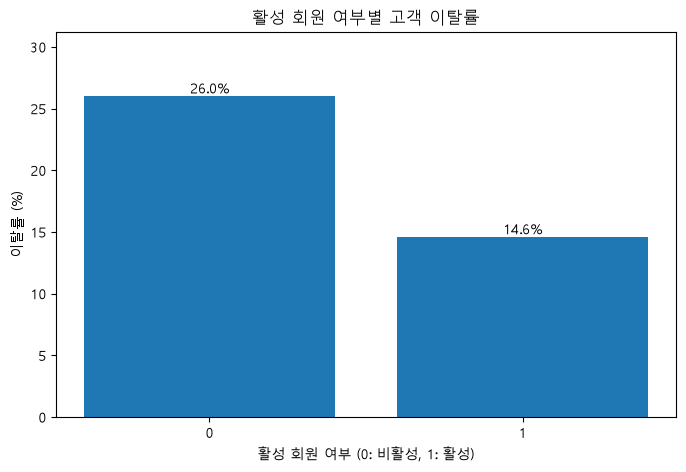

In [22]:
# 활성 회원 여부별 이탈률 계산
active_result = df_plot.groupby('IsActiveMember')['Exited'].mean() * 100

# 이탈률 내림차순 정렬
active_result = active_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(8, 5))
bars = plt.bar(active_result.index.astype(str), active_result.values)

# 막대 위에 이탈률 표시
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{bar.get_height():.1f}%', ha='center', va='bottom')

plt.title('활성 회원 여부별 고객 이탈률')
plt.xlabel('활성 회원 여부 (0: 비활성, 1: 활성)')
plt.ylabel('이탈률 (%)')
plt.ylim(0, active_result.max() * 1.2)
plt.show()

#### 잔액 구간별 이탈률

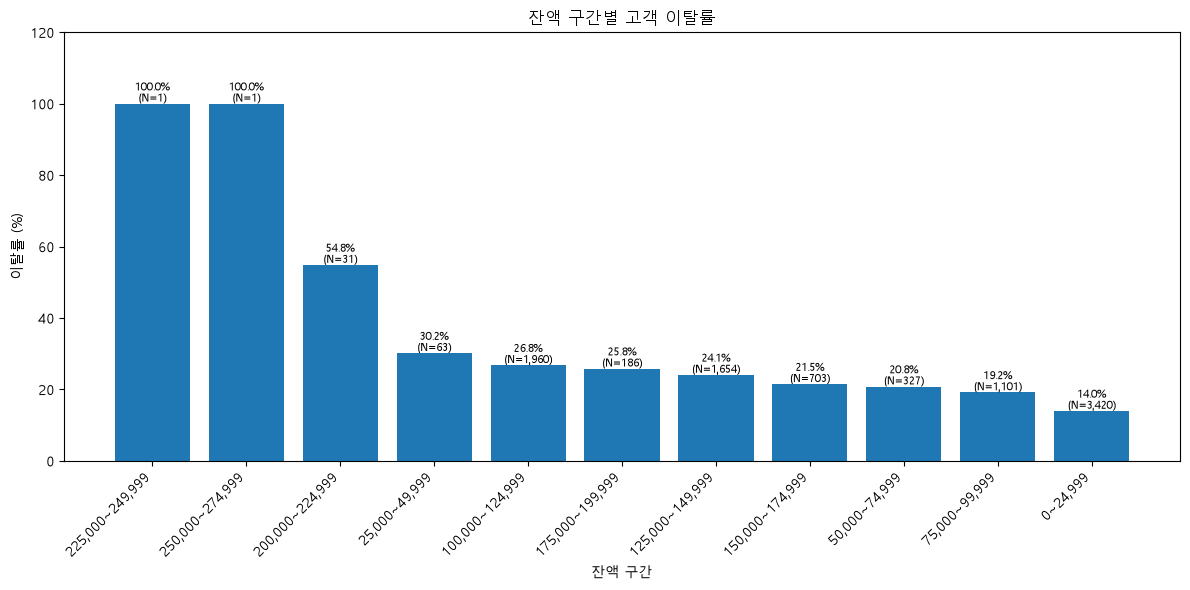

,이탈률,고객수
Balance_group,,
"225,000~249,999",100.000000,1
"250,000~274,999",100.000000,1
"200,000~224,999",54.838710,31
"25,000~49,999",30.158730,63
"100,000~124,999",26.785714,1960
"175,000~199,999",25.806452,186
"125,000~149,999",24.062878,1654
"150,000~174,999",21.479374,703
"50,000~74,999",20.795107,327


In [26]:
# 잔액 구간 설정 (25,000 단위)
bins = list(range(0, 275001, 25000))
labels = [f'{bins[i]:,}~{bins[i+1]-1:,}' for i in range(len(bins)-1)]

# 잔액 구간 생성
df_plot['Balance_group'] = pd.cut(
    df_plot['Balance'],
    bins=bins,
    labels=labels,
    right=False
)

# 구간별 이탈률과 고객 수 계산
balance_result = df_plot.groupby('Balance_group', observed=True)['Exited'].agg(
    이탈률='mean',
    고객수='count'
)

# 이탈률을 백분율로 변환
balance_result['이탈률'] = balance_result['이탈률'] * 100

# 이탈률 내림차순 정렬
balance_result = balance_result.sort_values('이탈률', ascending=False)

# 막대그래프 작성
plt.figure(figsize=(12, 6))
bars = plt.bar(balance_result.index.astype(str), balance_result['이탈률'])

# 이탈률과 고객 수 표시
for i, bar in enumerate(bars):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.1f}%\n(N={balance_result['고객수'].iloc[i]:,})",
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.title('잔액 구간별 고객 이탈률')
plt.xlabel('잔액 구간')
plt.ylabel('이탈률 (%)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, balance_result['이탈률'].max() * 1.2)
plt.tight_layout()
plt.show()

# 분석 결과 확인
display(balance_result)

#### 신용점수 구간별 이탈률

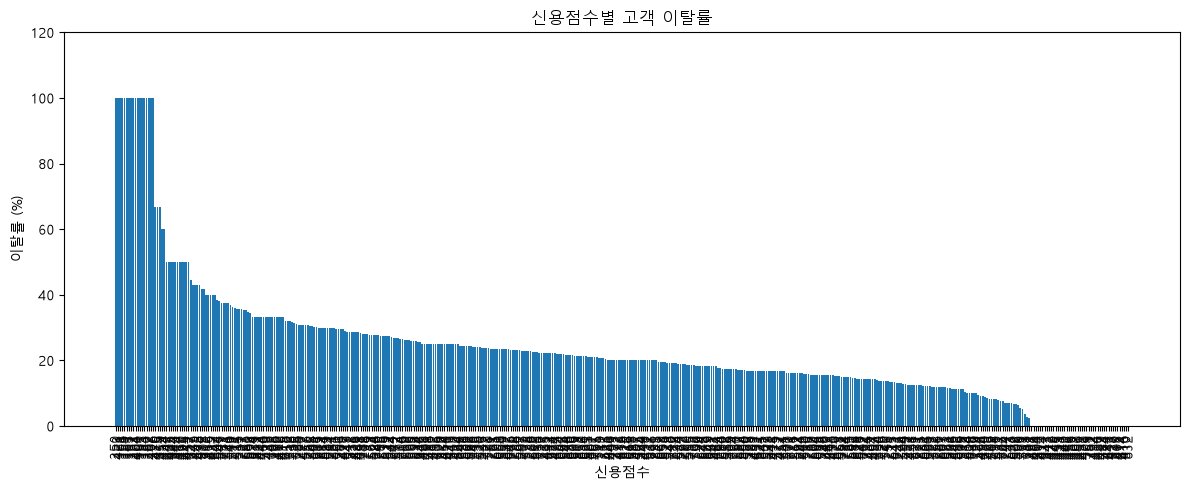

In [24]:
# 신용점수별 이탈률 계산
credit_result = df_plot.groupby('CreditScore')['Exited'].mean() * 100

# 이탈률 내림차순 정렬
credit_result = credit_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(12, 5))
bars = plt.bar(credit_result.index.astype(int).astype(str), credit_result.values)

# 그래프 제목 및 축 설정
plt.title('신용점수별 고객 이탈률')
plt.xlabel('신용점수')
plt.ylabel('이탈률 (%)')

# X축 숫자 표시 간격 조정
plt.xticks(rotation=90)
plt.ylim(0, credit_result.max() * 1.2)

plt.tight_layout()
plt.show()

#### EstimatedSalary별 이탈률

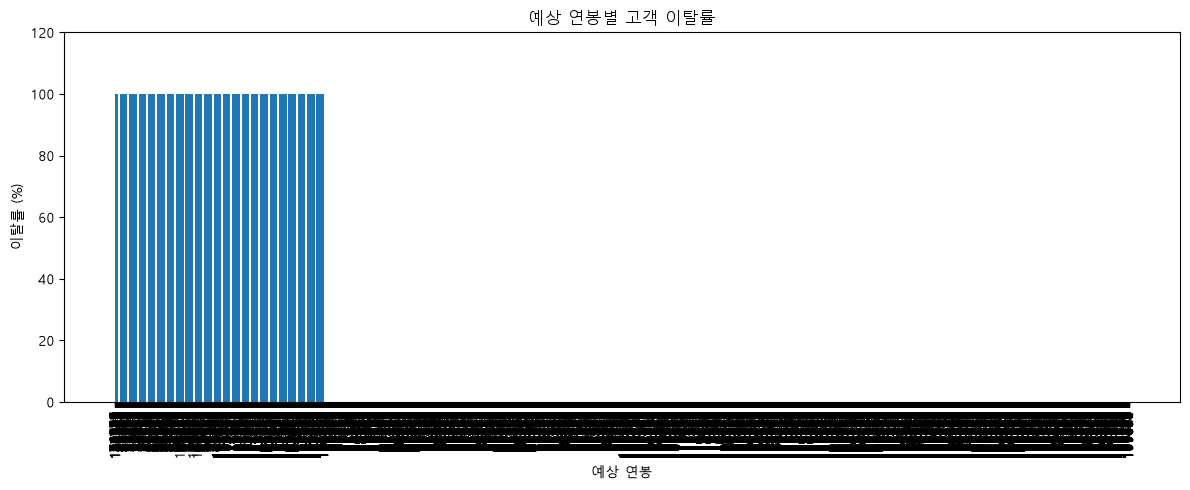

In [25]:
# 예상 연봉별 이탈률 계산
salary_result = df_plot.groupby('EstimatedSalary')['Exited'].mean() * 100

# 이탈률 내림차순 정렬
salary_result = salary_result.sort_values(ascending=False)

# 막대그래프 작성
plt.figure(figsize=(12, 5))
bars = plt.bar(salary_result.index.astype(int).astype(str), salary_result.values)

# 그래프 제목 및 축 설정
plt.title('예상 연봉별 고객 이탈률')
plt.xlabel('예상 연봉')
plt.ylabel('이탈률 (%)')

# X축 숫자 표시 간격 조정
plt.xticks(rotation=90)
plt.ylim(0, salary_result.max() * 1.2)

plt.tight_layout()
plt.show()

## 학습용 데이터와 평가용 데이터 생성

In [32]:
# 입력 데이터(X): Exited 컬럼 제외
X = df2.drop(columns=['Exited'])

# 정답 데이터(y): Exited 컬럼
y = df2['Exited']

# 데이터 크기 확인
print('입력 데이터 크기:', X.shape)
print('정답 데이터 크기:', y.shape)

입력 데이터 크기: (9447, 14)
정답 데이터 크기: (9447,)


In [33]:
# 필요한 라이브러리
from sklearn.model_selection import train_test_split

# 학습용 데이터와 평가용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 데이터 크기 확인
print('학습용 입력 데이터:', X_train.shape)
print('평가용 입력 데이터:', X_test.shape)
print('학습용 정답 데이터:', y_train.shape)
print('평가용 정답 데이터:', y_test.shape)

학습용 입력 데이터: (7557, 14)
평가용 입력 데이터: (1890, 14)
학습용 정답 데이터: (7557,)
평가용 정답 데이터: (1890,)


In [34]:
# 학습용 데이터와 평가용 데이터의 이탈 비율 확인
print('학습용 데이터 이탈 비율')
display(y_train.value_counts(normalize=True) * 100)

print('평가용 데이터 이탈 비율')
display(y_test.value_counts(normalize=True) * 100)

학습용 데이터 이탈 비율


Exited
0    79.714172
1    20.285828
Name: proportion, dtype: float64

평가용 데이터 이탈 비율


Exited
0    79.68254
1    20.31746
Name: proportion, dtype: float64

## 표준화

In [35]:
# 표준화 라이브러리
from sklearn.preprocessing import StandardScaler

In [36]:
# 표준화 모델 생성
scaler = StandardScaler()

# 학습용 데이터로 평균과 표준편차 계산
X_train_scaled = scaler.fit_transform(X_train)

# 평가용 데이터는 학습용 데이터의 기준으로 변환
X_test_scaled = scaler.transform(X_test)

In [37]:
# 표준화 결과를 DataFrame으로 변환
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# 표준화 결과 확인
display(X_train_scaled.head())

# 평균과 표준편차 확인
display(X_train_scaled.agg(['mean', 'std']).T)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Age_step,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
7482,-0.392373,0.029008,1.378627,0.800473,0.791707,-1.549019,-1.002783,-1.459143,-0.256286,-0.999339,1.730982,-0.577503,-0.911897,0.911897
4687,0.044338,-0.331342,-1.388605,0.481867,-0.916725,0.645570,0.997225,-0.294689,-0.256286,-0.999339,-0.577707,1.731593,1.096615,-1.096615
9164,-0.070039,-0.811808,-0.004989,0.154633,-0.916725,0.645570,0.997225,-0.450620,-0.256286,-0.999339,-0.577707,1.731593,1.096615,-1.096615
3039,-1.109827,-1.772739,-1.388605,0.322510,-0.916725,0.645570,-1.002783,-1.117121,-1.424410,1.000662,-0.577707,-0.577503,-0.911897,0.911897
8001,-1.546538,-0.331342,0.340915,-1.225069,0.791707,0.645570,0.997225,-0.334322,-0.256286,1.000662,-0.577707,-0.577503,1.096615,-1.096615


,mean,std
CreditScore,1.777062e-16,1.000066
Age,-3.178026e-16,1.000066
Tenure,3.760978e-17,1.000066
Balance,-4.137076e-17,1.000066
NumOfProducts,-9.167383e-17,1.000066
HasCrCard,6.205613e-17,1.000066
IsActiveMember,9.402445e-18,1.000066
EstimatedSalary,-7.145858e-17,1.000066
Age_step,2.783124e-16,1.000066
Geography_France,6.769760e-17,1.000066


## 모델

### LogisticRegression(로지스틱 회기) 모델

#### 모델 생성 및 학습

In [38]:
# 필요한 모델 클래스 임포트
from sklearn.linear_model import LogisticRegression

# 모델 생성
model_lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# 모델 학습
model_lr.fit(X_train_scaled, y_train)

print('Logistic Regression 학습 완료')

Logistic Regression 학습 완료


In [39]:
# 평가용 데이터 예측
pred_lr = model_lr.predict(X_test_scaled)

# 필요한 평가 지표 임포트
from sklearn.metrics import accuracy_score, classification_report

# 정확도 계산
acc_lr = accuracy_score(y_test, pred_lr)

# 결과 출력
print(f'Logistic Regression 정확도: {acc_lr:.4f}')

# 정밀도, 재현율, F1-score 확인
print(classification_report(y_test, pred_lr))

Logistic Regression 정확도: 0.8233
              precision    recall  f1-score   support

           0       0.85      0.95      0.90      1506
           1       0.63      0.32      0.42       384

    accuracy                           0.82      1890
   macro avg       0.74      0.63      0.66      1890
weighted avg       0.80      0.82      0.80      1890



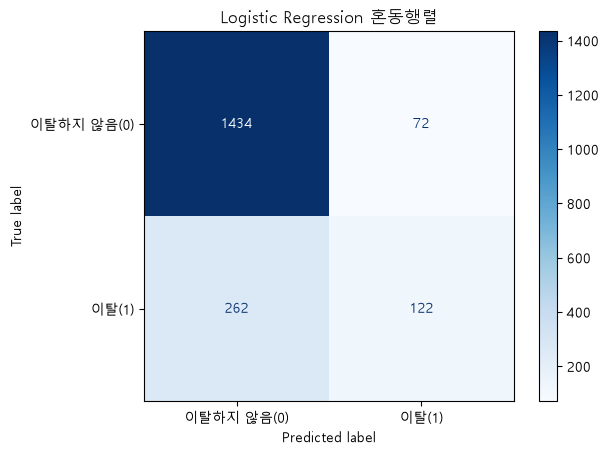

In [40]:
# 혼동행렬 라이브러리 임포트
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 혼동행렬 생성
cm_lr = confusion_matrix(y_test, pred_lr)

# 혼동행렬 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['이탈하지 않음(0)', '이탈(1)']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression 혼동행렬')
plt.show()

### 고도화

#### GridSearchCV 하이퍼파라미터 튜닝

In [41]:
# 필요한 라이브러리 임포트
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Logistic Regression 모델 생성
lr = LogisticRegression(
    random_state=42,
    max_iter=1000,
    solver='liblinear'
)

# 하이퍼파라미터 탐색 범위 설정
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'class_weight': [None, 'balanced']
}

# GridSearchCV 생성
grid_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

# 학습용 데이터로 최적의 하이퍼파라미터 탐색
grid_lr.fit(X_train_scaled, y_train)

# 최적의 파라미터 및 교차검증 성능 확인
print('최적의 하이퍼파라미터:', grid_lr.best_params_)
print(f'최고 교차검증 F1-score: {grid_lr.best_score_:.4f}')

최적의 하이퍼파라미터: {'C': 10, 'class_weight': 'balanced', 'penalty': 'l2'}
최고 교차검증 F1-score: 0.5207


#### 고도화 모델의 최종 평가

In [42]:
# 최적의 하이퍼파라미터를 적용한 모델 생성
best_lr = grid_lr.best_estimator_

# 테스트 데이터 예측
pred_lr_tuned = best_lr.predict(X_test_scaled)

# 모델 평가
from sklearn.metrics import accuracy_score, classification_report

# 정확도 확인
acc_lr_tuned = accuracy_score(y_test, pred_lr_tuned)

print(f'Logistic Regression 튜닝 정확도: {acc_lr_tuned:.4f}')

# 정밀도, 재현율, F1-score 확인
print(classification_report(y_test, pred_lr_tuned))

Logistic Regression 튜닝 정확도: 0.7323
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1506
           1       0.41      0.68      0.51       384

    accuracy                           0.73      1890
   macro avg       0.65      0.71      0.66      1890
weighted avg       0.80      0.73      0.75      1890



### SVM 기본 모델

In [43]:
# 필요한 라이브러리 임포트
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# SVM 모델 생성
model_svc = SVC(random_state=42)

# 모델 학습
model_svc.fit(X_train_scaled, y_train)

# 테스트 데이터 예측
pred_svc = model_svc.predict(X_test_scaled)

# 정확도 평가
acc_svc = accuracy_score(y_test, pred_svc)

print(f'SVM 정확도: {acc_svc:.4f}')

# 분류 성능 평가
print(classification_report(y_test, pred_svc))

SVM 정확도: 0.8513
              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1506
           1       0.77      0.38      0.51       384

    accuracy                           0.85      1890
   macro avg       0.82      0.68      0.71      1890
weighted avg       0.84      0.85      0.83      1890



#### SVM 하이퍼파라미터 튜닝

In [44]:
# 필요한 라이브러리 임포트
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# SVM 모델 생성
svc = SVC(random_state=42)

# 하이퍼파라미터 탐색 범위 설정
param_grid_svc = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto'],
    'class_weight': [None, 'balanced']
}

# GridSearchCV 생성
grid_svc = GridSearchCV(
    estimator=svc,
    param_grid=param_grid_svc,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

# 학습 데이터로 최적의 하이퍼파라미터 탐색
grid_svc.fit(X_train_scaled, y_train)

# 최적의 파라미터 및 교차검증 성능 확인
print('최적의 하이퍼파라미터:', grid_svc.best_params_)
print(f'최고 교차검증 F1-score: {grid_svc.best_score_:.4f}')

최적의 하이퍼파라미터: {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}
최고 교차검증 F1-score: 0.5931


#### 튜닝 SVM 최종 평가

In [45]:
# 최적의 하이퍼파라미터를 적용한 모델 생성
best_svc = grid_svc.best_estimator_

# 테스트 데이터 예측
pred_svc_tuned = best_svc.predict(X_test_scaled)

# 모델 평가
from sklearn.metrics import accuracy_score, classification_report

# 정확도 확인
acc_svc_tuned = accuracy_score(y_test, pred_svc_tuned)

print(f'SVM 튜닝 정확도: {acc_svc_tuned:.4f}')

# 정밀도, 재현율, F1-score 확인
print(classification_report(y_test, pred_svc_tuned))

SVM 튜닝 정확도: 0.7884
              precision    recall  f1-score   support

           0       0.92      0.81      0.86      1506
           1       0.49      0.72      0.58       384

    accuracy                           0.79      1890
   macro avg       0.70      0.76      0.72      1890
weighted avg       0.83      0.79      0.80      1890



### Decision Tree 기본 모델

In [46]:
# 필요한 라이브러리 임포트
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Decision Tree 모델 생성
model_dt = DecisionTreeClassifier(random_state=42)

# 모델 학습
model_dt.fit(X_train_scaled, y_train)

# 테스트 데이터 예측
pred_dt = model_dt.predict(X_test_scaled)

# 정확도 평가
acc_dt = accuracy_score(y_test, pred_dt)

print(f'Decision Tree 정확도: {acc_dt:.4f}')

# 분류 성능 평가
print(classification_report(y_test, pred_dt))

Decision Tree 정확도: 0.7958
              precision    recall  f1-score   support

           0       0.87      0.88      0.87      1506
           1       0.50      0.47      0.48       384

    accuracy                           0.80      1890
   macro avg       0.68      0.67      0.68      1890
weighted avg       0.79      0.80      0.79      1890



#### Decision Tree 하이퍼파라미터 튜닝

In [47]:
# 필요한 라이브러리 임포트
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Decision Tree 모델 생성
dt = DecisionTreeClassifier(random_state=42)

# 하이퍼파라미터 탐색 범위 설정
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced']
}

# GridSearchCV 생성
grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

# 학습 데이터로 최적의 하이퍼파라미터 탐색
grid_dt.fit(X_train_scaled, y_train)

# 최적의 파라미터 및 교차검증 성능 확인
print('최적의 하이퍼파라미터:', grid_dt.best_params_)
print(f'최고 교차검증 F1-score: {grid_dt.best_score_:.4f}')

최적의 하이퍼파라미터: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 10, 'min_samples_split': 2}
최고 교차검증 F1-score: 0.5737


#### 튜닝 Decision Tree 최종 평가

In [48]:
# 최적의 하이퍼파라미터를 적용한 모델 생성
best_dt = grid_dt.best_estimator_

# 테스트 데이터 예측
pred_dt_tuned = best_dt.predict(X_test_scaled)

# 모델 평가
from sklearn.metrics import accuracy_score, classification_report

# 정확도 확인
acc_dt_tuned = accuracy_score(y_test, pred_dt_tuned)

print(f'Decision Tree 튜닝 정확도: {acc_dt_tuned:.4f}')

# 분류 성능 평가
print(classification_report(y_test, pred_dt_tuned))

Decision Tree 튜닝 정확도: 0.7889
              precision    recall  f1-score   support

           0       0.92      0.81      0.86      1506
           1       0.49      0.71      0.58       384

    accuracy                           0.79      1890
   macro avg       0.70      0.76      0.72      1890
weighted avg       0.83      0.79      0.80      1890



### Random Forest 기본 모델

In [49]:
# 필요한 라이브러리 임포트
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Random Forest 모델 생성
model_rf = RandomForestClassifier(random_state=42)

# 모델 학습
model_rf.fit(X_train_scaled, y_train)

# 테스트 데이터 예측
pred_rf = model_rf.predict(X_test_scaled)

# 정확도 평가
acc_rf = accuracy_score(y_test, pred_rf)

print(f'Random Forest 정확도: {acc_rf:.4f}')

# 분류 성능 평가
print(classification_report(y_test, pred_rf))

Random Forest 정확도: 0.8545
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1506
           1       0.75      0.43      0.54       384

    accuracy                           0.85      1890
   macro avg       0.81      0.70      0.73      1890
weighted avg       0.84      0.85      0.84      1890



#### Random Forest 하이퍼파라미터 튜닝

In [50]:
# 필요한 라이브러리 임포트
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Random Forest 모델 생성
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# 하이퍼파라미터 탐색 범위 설정
param_dist_rf = {
    'n_estimators': randint(100, 501),
    'max_depth': [None, 5, 7, 10, 15, 20],
    'min_samples_split': randint(2, 21),
    'min_samples_leaf': randint(1, 11),
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

# RandomizedSearchCV 생성
random_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist_rf,
    n_iter=30,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1
)

# 학습 데이터로 최적의 하이퍼파라미터 탐색
random_rf.fit(X_train_scaled, y_train)

# 최적의 파라미터 및 교차검증 성능 확인
print('최적의 하이퍼파라미터:', random_rf.best_params_)
print(f'최고 교차검증 F1-score: {random_rf.best_score_:.4f}')

최적의 하이퍼파라미터: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 9, 'n_estimators': 487}
최고 교차검증 F1-score: 0.6112


#### 튜닝 Random Forest 최종 평가

In [51]:
# 최적의 하이퍼파라미터를 적용한 모델 생성
best_rf = random_rf.best_estimator_

# 테스트 데이터 예측
pred_rf_tuned = best_rf.predict(X_test_scaled)

# 모델 평가
from sklearn.metrics import accuracy_score, classification_report

# 정확도 확인
acc_rf_tuned = accuracy_score(y_test, pred_rf_tuned)

print(f'Random Forest 튜닝 정확도: {acc_rf_tuned:.4f}')

# 분류 성능 평가
print(classification_report(y_test, pred_rf_tuned))

Random Forest 튜닝 정확도: 0.8196
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      1506
           1       0.55      0.64      0.59       384

    accuracy                           0.82      1890
   macro avg       0.73      0.75      0.74      1890
weighted avg       0.83      0.82      0.82      1890



#### 모델 성능 자동 비교 코드

In [52]:
# 필요한 라이브러리 임포트
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 모델별 예측 결과 등록
models = {
    'Logistic 기본': pred_lr,
    'Logistic 튜닝': pred_lr_tuned,
    'SVM 기본': pred_svc,
    'SVM 튜닝': pred_svc_tuned,
    'Decision Tree 기본': pred_dt,
    'Decision Tree 튜닝': pred_dt_tuned,
    'Random Forest 기본': pred_rf,
    'Random Forest 튜닝': pred_rf_tuned
}

# 모델별 평가 결과 저장
results = []

for model_name, pred in models.items():

    # 평가 지표 계산
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred, pos_label=1)
    recall = recall_score(y_test, pred, pos_label=1)
    f1 = f1_score(y_test, pred, pos_label=1)

    # 결과 저장
    results.append({
        '모델': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1
    })

# DataFrame 생성
df_results = pd.DataFrame(results)

# F1-score 기준 내림차순 정렬
df_results = df_results.sort_values(
    by='F1-score',
    ascending=False
).reset_index(drop=True)

# 결과 표 출력
display(
    df_results.style
    .format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.2f}',
        'Recall': '{:.2f}',
        'F1-score': '{:.2f}'
    })
    .highlight_max(
        subset=['F1-score'],
        color='lightgreen'
    )
)

# 최고 성능 모델 확인
best_model = df_results.iloc[0]

print('=' * 50)
print(f"현재 1위 모델: {best_model['모델']}")
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"F1-score: {best_model['F1-score']:.4f}")
print('=' * 50)

,모델,Accuracy,Precision,Recall,F1-score
0,Random Forest 튜닝,0.8196,0.55,0.64,0.59
1,SVM 튜닝,0.7884,0.49,0.72,0.58
2,Decision Tree 튜닝,0.7889,0.49,0.71,0.58
3,Random Forest 기본,0.8545,0.75,0.43,0.54
4,SVM 기본,0.8513,0.77,0.38,0.51
5,Logistic 튜닝,0.7323,0.41,0.68,0.51
6,Decision Tree 기본,0.7958,0.50,0.47,0.48
7,Logistic 기본,0.8233,0.63,0.32,0.42


현재 1위 모델: Random Forest 튜닝
Accuracy: 0.8196
F1-score: 0.5916


### XGBoost 기본 모델 학습

In [53]:
# 필요한 라이브러리 임포트
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# XGBoost 모델 생성
model_xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

# 모델 학습
model_xgb.fit(X_train_scaled, y_train)

# 테스트 데이터 예측
pred_xgb = model_xgb.predict(X_test_scaled)

# 정확도 평가
acc_xgb = accuracy_score(y_test, pred_xgb)

print(f'XGBoost 정확도: {acc_xgb:.4f}')

# 분류 성능 평가
print(classification_report(y_test, pred_xgb))

XGBoost 정확도: 0.8444
              precision    recall  f1-score   support

           0       0.87      0.94      0.91      1506
           1       0.67      0.46      0.54       384

    accuracy                           0.84      1890
   macro avg       0.77      0.70      0.72      1890
weighted avg       0.83      0.84      0.83      1890



#### XGBoost 하이퍼파라미터 튜닝

In [54]:
# 필요한 라이브러리 임포트
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# XGBoost 모델 생성
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    n_jobs=1
)

# 하이퍼파라미터 탐색 범위 설정
param_dist_xgb = {
    'n_estimators': randint(100, 501),
    'max_depth': randint(3, 9),
    'learning_rate': uniform(0.01, 0.19),
    'subsample': uniform(0.7, 0.3),
    'colsample_bytree': uniform(0.7, 0.3),
    'min_child_weight': randint(1, 8),
    'scale_pos_weight': [1, 2, 3]
}

# RandomizedSearchCV 생성
random_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist_xgb,
    n_iter=30,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1
)

# 학습 데이터로 최적의 하이퍼파라미터 탐색
random_xgb.fit(X_train_scaled, y_train)

# 최적의 파라미터 및 교차검증 성능 확인
print('최적의 하이퍼파라미터:', random_xgb.best_params_)
print(f'최고 교차검증 F1-score: {random_xgb.best_score_:.4f}')

최적의 하이퍼파라미터: {'colsample_bytree': np.float64(0.7886901057513142), 'learning_rate': np.float64(0.030043909367751413), 'max_depth': 6, 'min_child_weight': 4, 'n_estimators': 207, 'scale_pos_weight': 2, 'subsample': np.float64(0.9649840776756604)}
최고 교차검증 F1-score: 0.6224


#### XGBoost 튜닝 모델 최종 평가

In [55]:
# 최적의 하이퍼파라미터를 적용한 모델 생성
best_xgb = random_xgb.best_estimator_

# 테스트 데이터 예측
pred_xgb_tuned = best_xgb.predict(X_test_scaled)

# 모델 평가
from sklearn.metrics import accuracy_score, classification_report

# 정확도 확인
acc_xgb_tuned = accuracy_score(y_test, pred_xgb_tuned)

print(f'XGBoost 튜닝 정확도: {acc_xgb_tuned:.4f}')

# 분류 성능 평가
print(classification_report(y_test, pred_xgb_tuned))

XGBoost 튜닝 정확도: 0.8513
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1506
           1       0.65      0.59      0.62       384

    accuracy                           0.85      1890
   macro avg       0.77      0.75      0.76      1890
weighted avg       0.85      0.85      0.85      1890



#### 통합 성능 비교표 갱신

In [57]:
# 모델별 예측 결과를 하나의 딕셔너리로 정리
models = {
    'Logistic 기본': pred_lr,
    'Logistic 튜닝': pred_lr_tuned,
    'SVM 기본': pred_svc,
    'SVM 튜닝': pred_svc_tuned,
    'Decision Tree 기본': pred_dt,
    'Decision Tree 튜닝': pred_dt_tuned,
    'Random Forest 기본': pred_rf,
    'Random Forest 튜닝': pred_rf_tuned,
    'XGBoost 기본': pred_xgb,
    'XGBoost 튜닝': pred_xgb_tuned
}

# 성능 지표 계산
results = []

for model_name, pred in models.items():
    results.append({
        '모델': model_name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, pos_label=1),
        'Recall': recall_score(y_test, pred, pos_label=1),
        'F1-score': f1_score(y_test, pred, pos_label=1)
    })

# DataFrame 생성 및 F1-score 기준 내림차순 정렬
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(
    by='F1-score',
    ascending=False
).reset_index(drop=True)

# 결과 출력
display(
    df_results.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.2f}',
        'Recall': '{:.2f}',
        'F1-score': '{:.2f}'
    }).highlight_max(
        subset=['F1-score'],
        color='lightgreen'
    )
)

# 현재 최고 성능 모델 확인
best_model = df_results.iloc[0]

print(f"현재 1위 모델: {best_model['모델']}")
print(f"최고 F1-score: {best_model['F1-score']:.2f}")

,모델,Accuracy,Precision,Recall,F1-score
0,XGBoost 튜닝,0.8513,0.65,0.59,0.62
1,Random Forest 튜닝,0.8196,0.55,0.64,0.59
2,SVM 튜닝,0.7884,0.49,0.72,0.58
3,Decision Tree 튜닝,0.7889,0.49,0.71,0.58
4,Random Forest 기본,0.8545,0.75,0.43,0.54
5,XGBoost 기본,0.8444,0.67,0.46,0.54
6,SVM 기본,0.8513,0.77,0.38,0.51
7,Logistic 튜닝,0.7323,0.41,0.68,0.51
8,Decision Tree 기본,0.7958,0.50,0.47,0.48
9,Logistic 기본,0.8233,0.63,0.32,0.42


현재 1위 모델: XGBoost 튜닝
최고 F1-score: 0.62


### Stacking 모델 생성 및 학습

In [58]:
# 필요한 라이브러리 임포트
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# 기본 모델 구성
estimators = [
    ('dt', DecisionTreeClassifier(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42, n_jobs=1)),
    ('xgb', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=1
    ))
]

# 최종 메타 모델 구성
final_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Stacking 모델 생성
model_stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=final_model,
    cv=5,
    n_jobs=-1
)

# 모델 학습
model_stacking.fit(X_train_scaled, y_train)

print("Stacking 모델 학습 완료")

Stacking 모델 학습 완료


#### 예측 및 성능 평가

In [59]:
# 테스트 데이터 예측
pred_stacking = model_stacking.predict(X_test_scaled)

# 정확도 확인
acc_stacking = accuracy_score(y_test, pred_stacking)
print(f'Stacking Accuracy: {acc_stacking:.4f}')

# 분류 성능 확인
print(classification_report(y_test, pred_stacking))

Stacking Accuracy: 0.8545
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1506
           1       0.73      0.45      0.56       384

    accuracy                           0.85      1890
   macro avg       0.80      0.70      0.74      1890
weighted avg       0.84      0.85      0.84      1890



#### 전체 모델 비교표 갱신

In [60]:
# 기존 모델 비교 딕셔너리에 Stacking 추가
models['Stacking'] = pred_stacking

# 성능 지표 재계산
results = []

for model_name, pred in models.items():
    results.append({
        '모델': model_name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, pos_label=1),
        'Recall': recall_score(y_test, pred, pos_label=1),
        'F1-score': f1_score(y_test, pred, pos_label=1)
    })

# F1-score 기준 내림차순 정렬
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(
    by='F1-score',
    ascending=False
).reset_index(drop=True)

# 비교표 출력
display(
    df_results.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.2f}',
        'Recall': '{:.2f}',
        'F1-score': '{:.2f}'
    }).highlight_max(
        subset=['F1-score'],
        color='lightgreen'
    )
)

# 최고 성능 모델 확인
best_model = df_results.iloc[0]

print(f"현재 1위 모델: {best_model['모델']}")
print(f"최고 F1-score: {best_model['F1-score']:.2f}")

,모델,Accuracy,Precision,Recall,F1-score
0,XGBoost 튜닝,0.8513,0.65,0.59,0.62
1,Random Forest 튜닝,0.8196,0.55,0.64,0.59
2,SVM 튜닝,0.7884,0.49,0.72,0.58
3,Decision Tree 튜닝,0.7889,0.49,0.71,0.58
4,Stacking,0.8545,0.73,0.45,0.56
5,Random Forest 기본,0.8545,0.75,0.43,0.54
6,XGBoost 기본,0.8444,0.67,0.46,0.54
7,SVM 기본,0.8513,0.77,0.38,0.51
8,Logistic 튜닝,0.7323,0.41,0.68,0.51
9,Decision Tree 기본,0.7958,0.50,0.47,0.48


현재 1위 모델: XGBoost 튜닝
최고 F1-score: 0.62


### Stacking 하이퍼파라미터 튜닝